In [29]:
import os
import os.path as op

import matplotlib.pyplot as plt

import hnn_core
from hnn_core.params import _short_name

from hnn_core import  simulate_dipole, read_dipole, MPIBackend, jones_2009_model


from urllib.request import urlretrieve

exp_dpl = read_dipole('/Users/katharinaduecker/Documents/projects_brown/hnn-data/MEG_detection_data/S1_SupraT.txt')
yes_dpl = read_dipole('/Users/katharinaduecker/Documents/projects_brown/hnn-data/MEG_detection_data/yes_trial_S1_ERP_all_avg.txt')

from hnn_core.dipole import _rmse

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'



In [30]:
from hnn_core.hnn_io import read_network_configuration
from hnn_core import read_params
from hnn_core.network import Network
which_erp = 'darcy'  # 'darcy', 'neymotin', 'jones2009'
if which_erp == 'darcy':
    net = read_network_configuration('/Users/katharinaduecker/Documents/projects_brown/hnn-data/network-configurations/ERPSupraT.json')
elif which_erp == 'neymotin':
    params = read_params('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/compare_jones2009/ERPYesSupraT.param')
    net = jones_2009_model(params=params, add_drives_from_params=True, legacy_mode=True) 
elif which_erp == 'jones2009':
    net = read_network_configuration('/Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/param/jones2009_base.json')



In [31]:
tstop = exp_dpl.times[-1]
scale_factor = 3000
smooth_window_len = 30

depths = list(list(range(0,2000,150)))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('probe1', electrode_pos, method='lsa')

dpl = simulate_dipole(net, tstop=tstop, n_trials=1)[0]

dpl.scale(scale_factor).smooth(smooth_window_len)

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Applying Jones baseline correction


In [32]:
import numpy as np
rmse = _rmse(dpl, exp_dpl,tstart=0,tstop=1000)

In [33]:
import numpy as np
from cmcrameri import cm
import matplotlib
step_cm = int(len(cm.hawaiiS.colors) / 19)
cm_neurons = np.array([[166,206,227], [31,120,180], [178,223,138],[51,160,44]])/255


cmap = matplotlib.colors.ListedColormap(cm_neurons)

col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
cmap_lines = matplotlib.colors.ListedColormap(col_lines)
cmap_lines

def assign_color(gid):
    for cell_type, gid_range in net.gid_ranges.items():
        if cell_type in list(cell_type_colors.keys()):
            if gid in gid_range:
                return cell_type_colors[cell_type]

In [34]:
from hnn_core.extracellular import _get_laminar_z_coords

contact_labels, delta = _get_laminar_z_coords(net.rec_arrays['probe1'][0].positions)
new_lim = contact_labels[0:len(contact_labels):1]/1000

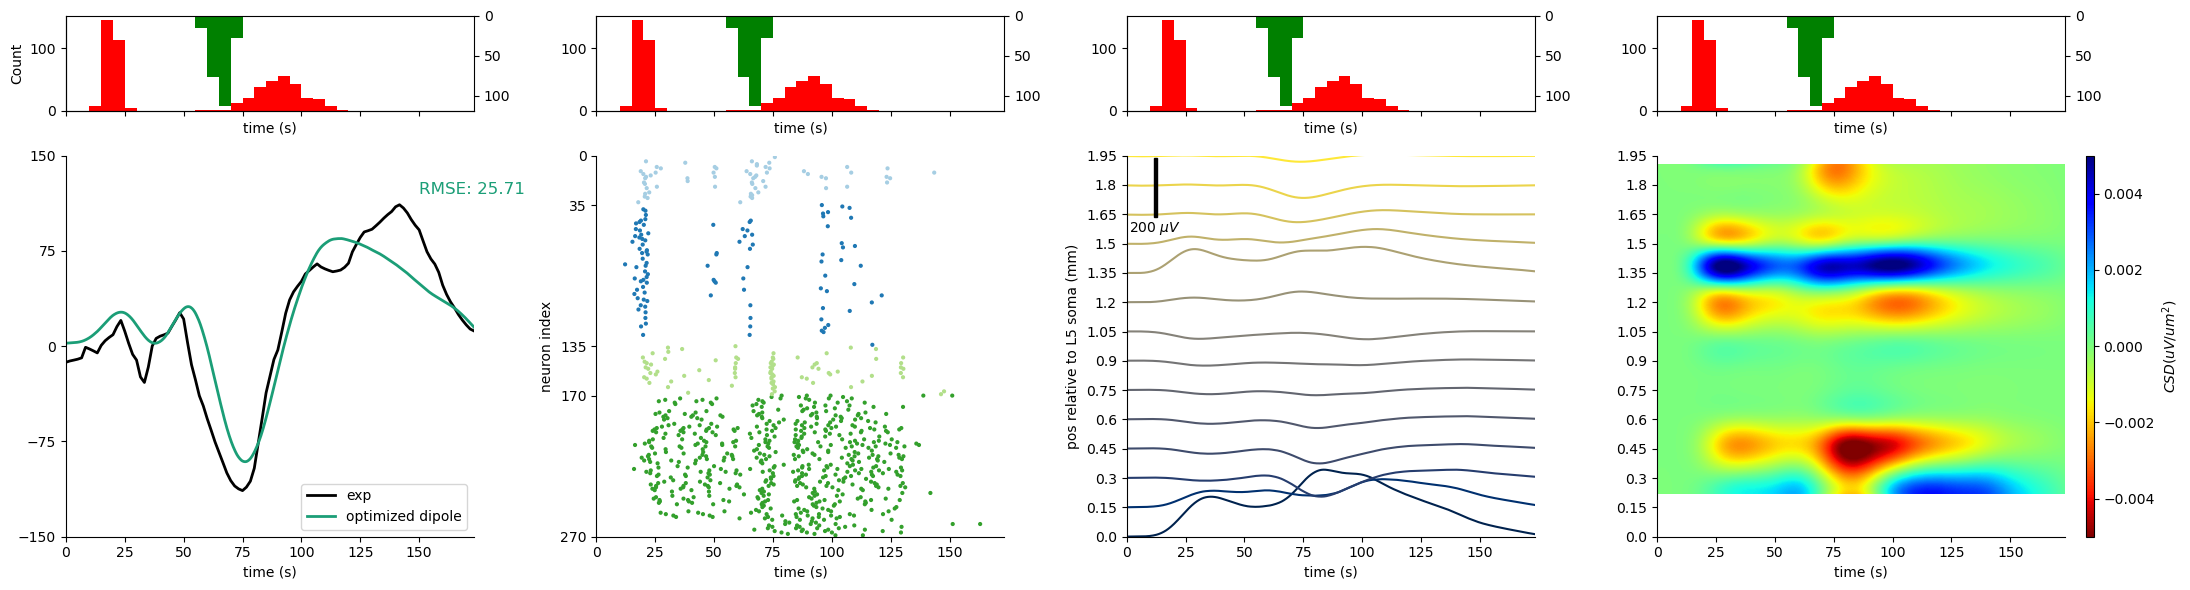

In [35]:
fig, ax = plt.subplots(2,4,figsize=(22,6), height_ratios=[0.25,1], sharex=True)

# drives
# proximal and distal histogram
spike_prox1 = np.array(net.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['evdist1']).reshape(-1,1)
spike_prox2 = np.array(net.cell_response.spike_times_by_type['evprox2']).reshape(-1,1)
bins = np.arange(0, tstop, 5)  # histogram bins

for i in range(4):
    ax[0,i].hist(spike_prox1, bins, color='r')
    #ax[0,i].set_ylim([0, 1500])

    if i == 0:
        ax[0,i].set_ylabel('Count')
    ax[0,i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0,i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    #ax1tw.set_ylim([0, 1500])
    ax1tw.invert_yaxis()

ax[1,0].plot(exp_dpl.times,exp_dpl.data['agg'], label='exp', color='k', linewidth=2)
ax[1,0].plot(dpl.times,dpl.data['agg'], label='optimized dipole', color=col_lines[0], linewidth=2)

ax[1,0].text(150, 120, 'RMSE: %.2f' %rmse, fontsize=12, color=col_lines[0])

ax[1,0].set_ylim([-150, 150])
ax[1,0].set_yticks([-150, -75, 0, 75, 150])
ax[1,0].legend(loc='lower right')

# spiking
I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I]
cell_types = ['L2_inhibitory', 'L2_pyramidal', 'L5_inhibitory', 'L5_pyramidal']
cell_type_colors = {'L2_basket': cmap.colors[0], 'L2_pyramidal': cmap.colors[1], 
               'L5_basket': cmap.colors[2], 'L5_pyramidal': cmap.colors[3]}

colors = [assign_color(gid) for gid in gids]

ax[1,1].scatter(times, gids, s=4, alpha=1., c=colors)
ax[1,1].set_ylabel('neuron index')
ax[1,1].set_xlim([0, 175])
ax[1,1].set_xlabel('time (ms)')
ax[1,1].set_ylim([0, 270])
ax[1,1].set_yticks([0, 35, 135, 170, 270])
ax[1,1].invert_yaxis()
ax[1,1].set_xticks(np.arange(0, 176, 25))
ax[1,1].set_xlim((0, 175))

net.rec_arrays['probe1'][0].smooth(smooth_window_len).plot_lfp(ax=ax[1,2], show=False, voltage_offset=100)
lfp_ticks = ax[1,2].get_yticks()
ax[1,2].set_yticks(np.linspace(lfp_ticks[0], lfp_ticks[-1], len(new_lim)))
ax[1,2].set_yticklabels(new_lim)
ax[1,2].set_ylabel('pos relative to L5 soma (mm)')
ax[1,2].set_ylim([lfp_ticks[0], lfp_ticks[-1]])

net.rec_arrays['probe1'][0].smooth(smooth_window_len).plot_csd(ax=ax[1,3], show=False, vmin=-0.005, vmax=0.005,sink='r' )
csd_ticks = ax[1,3].get_yticks()
ax[1,3].set_yticks(np.linspace(csd_ticks[0], csd_ticks[-1], len(new_lim)))
ax[1,3].set_yticklabels(new_lim)
ax[1,3].set_ylabel('')
ax = ax.flatten()
for a in ax:
    a.set_xlabel('time (s)')
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

fig.tight_layout()


fig.savefig(os.path.join(pathfig,f'dpl_spiking_lfp_csd_{which_erp}.png'), dpi=300, bbox_inches='tight')



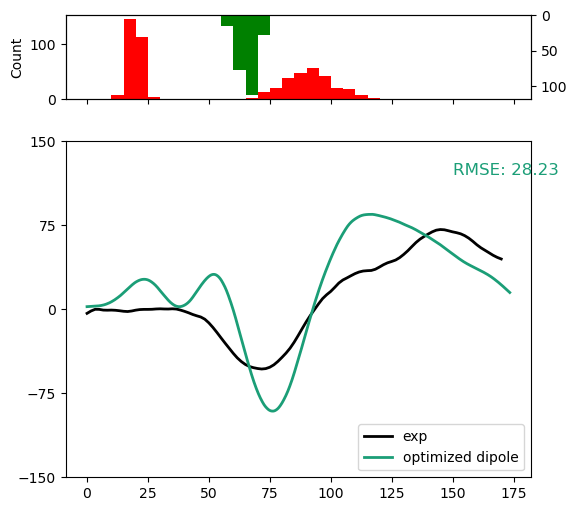

In [36]:
yes_rmse = _rmse(yes_dpl, dpl, tstart=0, tstop=1000)
fig, ax = plt.subplots(2,1,figsize=(6,6), height_ratios=[0.25,1], sharex=True)

# drives
# proximal and distal histogram
spike_prox1 = np.array(net.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['evdist1']).reshape(-1,1)
spike_prox2 = np.array(net.cell_response.spike_times_by_type['evprox2']).reshape(-1,1)
bins = np.arange(0, tstop, 5)  # histogram bins

ax[0].hist(spike_prox1, bins, color='r')
ax[0].set_ylabel('Count')
ax[0].hist(spike_prox2, bins, color='r')

ax1tw = ax[0].twinx()
ax1tw.hist(spike_dist, bins, color='g')
#ax1tw.set_ylim([0, 1500])
ax1tw.invert_yaxis()

ax[1].plot(yes_dpl.times,yes_dpl.data['agg'], label='exp', color='k', linewidth=2)
ax[1].plot(dpl.times,dpl.data['agg'], label='optimized dipole', color=col_lines[0], linewidth=2)

ax[1].text(150, 120, 'RMSE: %.2f' %yes_rmse, fontsize=12, color=col_lines[0])

ax[1].set_ylim([-150, 150])
ax[1].set_yticks([-150, -75, 0, 75, 150])
ax[1].legend(loc='lower right')

fig.savefig(os.path.join(pathfig,f'neymotin_vs_yes.png'), dpi=300, bbox_inches='tight')


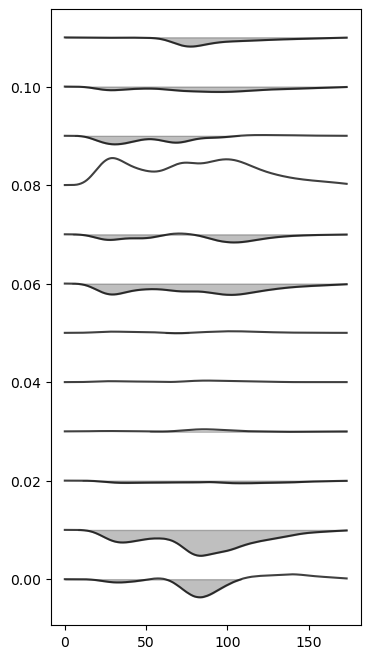

In [37]:
lfp = net.rec_arrays['probe1'][0].smooth(smooth_window_len)
lfp = lfp.voltages[0]
csd2d = np.zeros((lfp.shape[0]-2, lfp.shape[1]))
for i in np.arange(1, lfp.shape[0]-1):
    csd2d[i-1, :] = - (lfp[i-1, :] - 2 * lfp[i, :] + lfp[i+1, :]) / delta ** 2

n_offsets = csd2d.shape[0]
trace_offsets = np.zeros((n_offsets, 1))
voltage_offset=0.01
trace_offsets = np.arange(n_offsets)[:, np.newaxis] * voltage_offset

fig, ax = plt.subplots(figsize=(4, 8))
for i in range(csd2d.shape[0]):
    ax.plot(net.cell_response.times, csd2d[i, :] + trace_offsets[i], color='k', alpha=0.75)
    sink_idx = csd2d[i,:] < 0
    ax.fill_between(net.cell_response.times[sink_idx], csd2d[i, sink_idx] + trace_offsets[i], + trace_offsets[i], color='k', alpha=0.25)

fig.savefig(os.path.join(pathfig,'csd2d_optimized_current.png'))
fig.savefig(os.path.join(pathfig,'csd2d_optimized_current.pdf'))

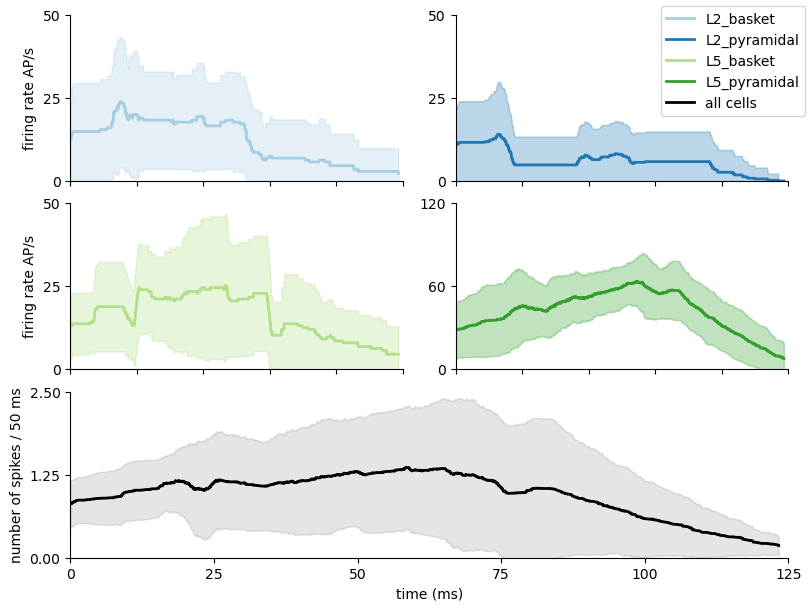

In [38]:
import numpy as np
# firing rates

fig = plt.figure(figsize=(8,6), layout="constrained")
spec = fig.add_gridspec(3, 2)

ax1 = [None] * 4
ax1[0] = fig.add_subplot(spec[0, 0])

ax1[1] = fig.add_subplot(spec[0, 1])

ax1[2] = fig.add_subplot(spec[1, 0])

ax1[3] = fig.add_subplot(spec[1, 1])

ax2 = fig.add_subplot(spec[2, :])


cols = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']

# 50 ms bin length
dt = np.diff(net.cell_response.times)[0]
bin_ms = 50
bin_l = int(bin_ms / dt)  # bin length in number of time points
frates_all = np.zeros((4, len(net.cell_response.times)-bin_l))

for i, cell_type in enumerate(cell_types):

    num_cells = net.gid_ranges[cell_type][-1]-net.gid_ranges[cell_type][0]+1
    frates_cell = np.zeros((num_cells, len(net.cell_response.times)-bin_l))
    frates_cell5ms = np.zeros((num_cells, len(net.cell_response.times)-int(5 / dt)))
    # Get the spike times for the current cell type
    spike_times_type = np.array(net.cell_response.spike_times_by_type[cell_type][0])
    spike_times = np.array(net.cell_response.spike_times[0])
    spike_gids = np.array(net.cell_response.spike_gids[0])
    for ti, t in enumerate(net.cell_response.times[:-bin_l]):
        spike_bool = (spike_times > t) & (spike_times < t + bin_ms)
        if (spike_bool).any():
            for g, gid in enumerate(net.gid_ranges[cell_type]):
                frates_cell[g, ti] = np.sum(gid == spike_gids[spike_bool])
        spike_bool = (spike_times > t) & (spike_times < t + 5)
        if (spike_bool).any():
            for g, gid in enumerate(net.gid_ranges[cell_type]):
                frates_cell5ms[g, ti] = np.sum(gid == spike_gids[spike_bool])
    frates_all[i, :] = np.mean(frates_cell, axis=0)

    #ax0.plot(net.cell_response.times[:-bin_l], frates_all[i, :], color=cm_neurons[i], linewidth=2)
    ax1[i].fill_between(net.cell_response.times[:-bin_l], np.mean(frates_cell/bin_ms*1000, axis=0) - np.std(frates_cell/bin_ms*1000, axis=0), np.mean(frates_cell/bin_ms*1000, axis=0) + np.std(frates_cell/bin_ms*1000, axis=0), alpha=0.3, color=cm_neurons[i])
    ax1[i].plot(net.cell_response.times[:-bin_l], np.mean(frates_cell/bin_ms*1000, axis=0), color=cm_neurons[i],label=cell_type, linewidth=2)
    ax1[i].set_ylim(bottom=0)
    ax1[i].set_xlim((0, 175))
    
ax2.plot(net.cell_response.times[:-bin_l], np.mean(frates_all, axis=0), color='k', label='all cells', linewidth=2)
ax2.fill_between(net.cell_response.times[:-bin_l], np.mean(frates_all, axis=0) - np.std(frates_all, axis=0), np.mean(frates_all, axis=0) + np.std(frates_all, axis=0), alpha=0.1, color='k')
ax2.set_ylabel('number of spikes / 50 ms')
    
#ax0.set_yticks(np.arange(0, 16, 5))
ax1[0].set_ylabel('firing rate AP/s')
ax1[2].set_ylabel('firing rate AP/s')


for i,a in enumerate(ax1):
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.set_xticks(np.arange(0, 175, 25))
    a.set_xticklabels([])
    a.set_xlim((0, 125))

    if i == 3:
        a.set_ylim((0, 100))
        a.set_yticks(np.arange(0, 121, 60))
    else:
        a.set_ylim((0, 50))
        a.set_yticks(np.arange(0, 51, 25))


ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_xticks(np.arange(0, 126, 25))
ax2.set_xlim((0, 125))
ax2.set_xlabel('time (ms)')
ax2.set_ylim((0, 2.5))
ax2.set_yticks(np.arange(0, 2.6, 1.25))
# ax2.set_yticks(np.arange(0, 11, 5))

fig.legend()
fig.savefig(os.path.join(pathfig,f'firing_rates_{which_erp}.png'), dpi=300, bbox_inches='tight')


In [39]:
net_no_ca = net.copy()

In [40]:
def net_block_ca(net_no_ca):
    # block Ca

    for section in net_no_ca.cell_types['L5_pyramidal'].sections:
        net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['ca']['gbar_ca'] = 0
        net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['cat']['gbar_ca'] = 0

    return net_no_ca

In [41]:
net_no_ca = net_block_ca(net_no_ca)

In [42]:
dpl_no_ca = simulate_dipole(net_no_ca, tstop=tstop, n_trials=1)[0]
dpl_no_ca.scale(scale_factor).smooth(smooth_window_len)

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Applying Jones baseline correction


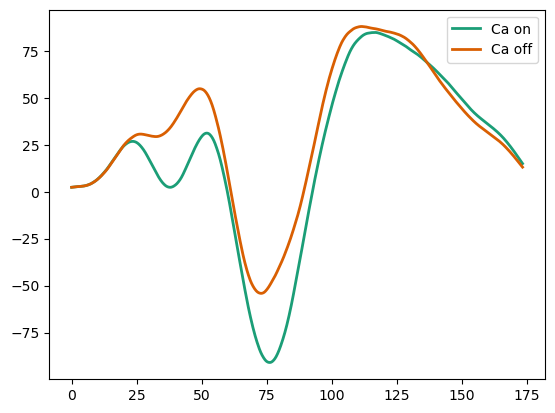

In [43]:
plt.plot(dpl.times, dpl.data['agg'], label='Ca on', color=col_lines[0], linewidth=2)
plt.plot(dpl_no_ca.times, dpl_no_ca.data['agg'], label='Ca off', color=col_lines[1], linewidth=2)
plt.legend()
